# 03 — Analisis Univariat
### Milestone M3 (dinilai saat UTS) · Exploratory Data Analysis (KMTI21133)

| | |
|---|---|
| **Nama tim** | Nunaaa |
| **Anggota** | Salma Haniya Rahma (0110225150)
| | Trisa Dhiya Nasywa (0110225049) |
| | Labibah Nurrahmah (0110225176) |
| | Indah Nurul Ayni (0110225121) |
| **Topik proyek** | Analisis Pola Penjualan Toko Ritel |
| **Tanggal** | 15 November 2026 |

**Notebook ini mengisi:** dimensi **Analisis univariat** (20) dan sebagian **Kualitas visualisasi** (15) pada Rubrik M3.

Satu variabel pada satu waktu: bagaimana bentuk distribusinya, berapa sebarannya,
adakah outlier, dan apa artinya bagi pertanyaan analisis Anda.

Yang membedakan nilai 4 dari nilai 2 bukan jumlah grafik, melainkan **tafsirannya**.
Memanggil `describe()` lalu berhenti bernilai 2.

---
> **Sebelum mengumpulkan:** jalankan **Kernel → Restart & Run All**. Notebook yang tidak dapat
> berjalan dari awal sampai akhir dianggap tidak memenuhi dimensi *ketepatan implementasi*.

In [ ]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from pathlib import Path

pd.set_option('display.width', 140)
pd.set_option('display.max_columns', 60)
plt.rcParams.update({
    'figure.dpi': 110, 'font.size': 10,
    'axes.titlesize': 11, 'axes.titleweight': 'bold',
    'axes.grid': True, 'grid.alpha': 0.25,
    'axes.spines.top': False, 'axes.spines.right': False,
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
})

DATA  = '#0E7490'   # warna utama
SOROT = '#C2410C'   # penyorot
REDUP = '#5B6672'

# Path relatif terhadap folder notebooks/ -- JANGAN diganti menjadi path absolut.
AKAR      = Path('..')
RAW       = AKAR / 'data' / 'raw'
PROCESSED = AKAR / 'data' / 'processed'
FIGURES   = AKAR / 'reports' / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)

In [ ]:
df = pd.read_csv("data_bersih.csv")

# Pastikan kolom tanggal diubah ke format datetime
df["Transaction Date"] = pd.to_datetime(df["Transaction Date"])

# Ekstraksi tambahan waktu
df["Bulan"] = df["Transaction Date"].dt.month
df["Tahun"] = df["Transaction Date"].dt.year

print(f"Dataset berhasil dimuat! Ukuran: {df.shape[0]} baris x {df.shape[1]} kolom")

Dataset berhasil dimuat! Ukuran: 12575 baris x 15 kolom


## 0. Variabel mana yang dianalisis, dan mengapa

Jangan menganalisis semua kolom. Pilih yang berkaitan dengan pertanyaan analisis Anda,
lalu sebutkan alasannya.

| Variabel | Tipe | Mengapa relevan dengan pertanyaan kami |
|----------|------|----------------------------------------|
| Price Per Unit | Numerik (rasio) | Menentukan nilai tiap transaksi; dibutuhkan untuk menjawab [P_]. Sebagian nilainya diimputasi dari Total Spent ÷ Quantity. |
| Quantity | Numerik (diskrit) | Ukuran jumlah barang per transaksi; dasar untuk [P_]. |
| Total Spent | Numerik (rasio) | Ukuran utama nilai transaksi; variabel hasil yang ingin dijelaskan pada [P_]. |
| Category | Kategorikal (nominal) | Pembanding antar kelompok produk pada [P_]. |
| Payment Method | Kategorikal (nominal) | Melihat apakah cara bayar berkaitan dengan nilai belanja, [P_]. |
| Location | Kategorikal (nominal) | Membandingkan toko fisik dan online, [P_]. |
| Discount Applied | Kategorikal (boolean) | Melihat apakah diskon berkaitan dengan nilai belanja, [P_]. Sepertiga datanya kosong. |

Variabel yang tidak dianalisis di notebook ini: **Item** dan **Transaction Date** ([alasan, misalnya: dipakai pada analisis tren waktu di 04 / tidak relevan dengan pertanyaan]).

## 1. Variabel numerik

Untuk setiap variabel: ringkasan angka, lalu histogram berpasangan dengan boxplot.

In [ ]:
NUMERIK = ['Price Per Unit', 'Quantity', 'Total Spent']

print(df[NUMERIK].describe().T.round(2).to_string())

                  count    mean    std  min   25%    50%    75%    max
Price Per Unit  12575.0   23.37  10.75  5.0  14.0   23.0   33.5   41.0
Quantity        11971.0    5.54   2.86  1.0   3.0    6.0    8.0   10.0
Total Spent     11971.0  129.65  94.75  5.0  51.0  108.5  192.0  410.0


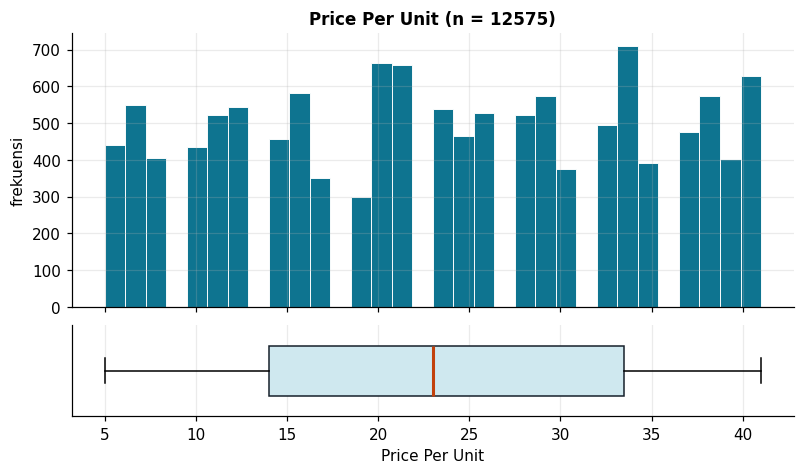

mean        23.37      median      23.00      selisih +0.37
std         10.75      IQR         19.50
skewness   -0.034
outlier menurut batas IQR :    0   (batas -15.25 .. 62.75)
outlier menurut |z| > 3   :    0


In [ ]:
import matplotlib as _mpl
_V = tuple(int(x) for x in _mpl.__version__.split('.')[:2])
ARAH = {'orientation': 'horizontal'} if _V >= (3, 10) else {'vert': False}   # kompatibel lintas versi

def potret(kolom, satuan=''):
    """Histogram + boxplot pada satu sumbu x, plus ringkasan angka."""
    d = df[kolom].dropna()
    q1, q3 = d.quantile([.25, .75]); iqr = q3 - q1
    bawah, atas = q1 - 1.5*iqr, q3 + 1.5*iqr
    z = (d - d.mean()).abs() / d.std()

    fig, ax = plt.subplots(2, 1, figsize=(7.2, 4.2), sharex=True,
                           layout='constrained',
                           gridspec_kw={'height_ratios': [3, 1]})
    ax[0].hist(d, bins=32, color=DATA, edgecolor='white', linewidth=.6)
    ax[0].set_ylabel('frekuensi')
    ax[0].set_title(f'{kolom} (n = {len(d)})')
    ax[1].boxplot(d, **ARAH, widths=.55, patch_artist=True,
                  boxprops=dict(facecolor='#CFE8EF', edgecolor='#16202B'),
                  medianprops=dict(color=SOROT, linewidth=2),
                  flierprops=dict(marker='o', markersize=4, markerfacecolor=DATA,
                                  markeredgecolor='none', alpha=.6))
    ax[1].set_yticks([]); ax[1].set_xlabel(f'{kolom} {satuan}'.strip())
    plt.show()

    print(f'mean   {d.mean():10.2f}      median {d.median():10.2f}'
          f'      selisih {d.mean()-d.median():+.2f}')
    print(f'std    {d.std():10.2f}      IQR    {iqr:10.2f}')
    print(f'skewness {stats.skew(d):8.3f}')
    print(f'outlier menurut batas IQR : {((d<bawah)|(d>atas)).sum():4d}   '
          f'(batas {bawah:.2f} .. {atas:.2f})')
    print(f'outlier menurut |z| > 3   : {(z>3).sum():4d}')

potret(NUMERIK[0])

**Tafsiran variabel 1.** Sebutkan bentuk distribusinya, bukti dari gambar **dan** dari
angka, lalu ukuran pemusatan mana yang lebih mewakili dan mengapa.

> _Distribusi Quantity hampir seragam (rata). Histogram menunjukkan nilai 1 sampai 10 muncul dengan frekuensi yang hampir sama, sekitar 1.150–1.230 baris per nilai, tanpa puncak atau ekor yang jelas. Angka mendukung gambar ini: skewness −0,01 (simetris), mean 5,54 dan median 6,00 hampir sama (selisih −0,46), serta tidak ada outlier (batas IQR −4,5 sampai 15,5, sedangkan data hanya 1–10). Karena distribusinya simetris dan tanpa outlier, mean maupun median sama-sama bisa dipakai, tetapi keduanya kurang informatif sebagai “nilai tipikal”, sebab setiap nilai sama seringnya. n yang dianalisis 11.971 baris (604 baris kosong tidak ikut)._

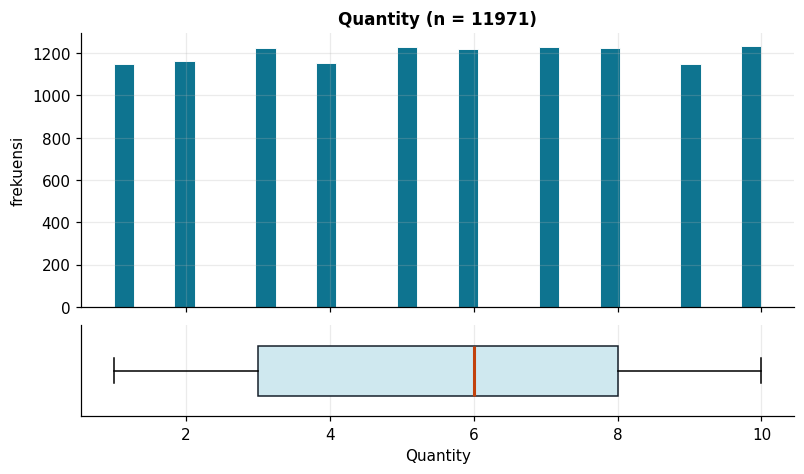

mean         5.54      median       6.00      selisih -0.46
std          2.86      IQR          5.00
skewness   -0.012
outlier menurut batas IQR :    0   (batas -4.50 .. 15.50)
outlier menurut |z| > 3   :    0


In [ ]:
potret(NUMERIK[1])

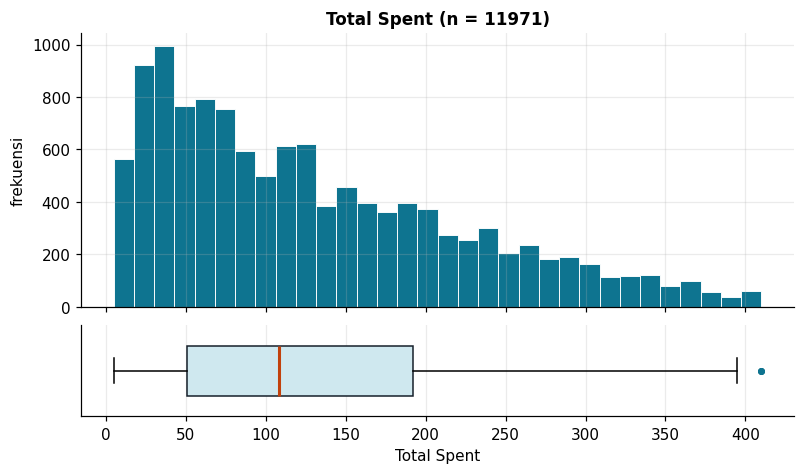

mean       129.65      median     108.50      selisih +21.15
std         94.75      IQR        141.00
skewness    0.831
outlier menurut batas IQR :   60   (batas -160.50 .. 403.50)
outlier menurut |z| > 3   :    0


In [ ]:
potret(NUMERIK[2])

**Tafsiran variabel 2.**

> _Total Spent berbentuk miring ke kanan: banyak transaksi bernilai kecil dan ekor panjang ke nilai besar. Histogram menunjukkan puncak di sekitar 50–100 yang menurun pelan hingga 410. Angkanya mendukung: mean (129,65) lebih besar daripada median (108,5), selisih +21,15, dan skewness [isi dari output, harusnya positif]. Karena miring kanan dan ada outlier di ekor atas, median lebih mewakili nilai tipikal karena tidak tertarik ekor. Bentuk ini wajar karena Total Spent adalah hasil kali Price Per Unit dan Quantity yang masing-masing tersebar hampir merata, dan hasil kali dua variabel seperti itu cenderung miring kanan. n = 11.971 (604 baris kosong tidak ikut).Dan Terdapat 60 transaksi (sekitar 0,5% dari 11.971) di atas batas IQR, semuanya bernilai 410, yaitu hasil kali harga tertinggi (41) dan jumlah tertinggi (10). Ini bukan anomali, melainkan batas atas alami dari data yang miring kanan._

In [ ]:
for col in ['Price Per Unit', 'Quantity', 'Total Spent']:
    s = df[col].dropna()
    print(f"Variabel: {col} | Mean: {s.mean():.2f} | Median: {s.median():.2f} | Skewness: {s.skew():.2f}")

Variabel: Price Per Unit | Mean: 23.37 | Median: 23.00 | Skewness: -0.03
Variabel: Quantity | Mean: 5.54 | Median: 6.00 | Skewness: -0.01
Variabel: Total Spent | Mean: 129.65 | Median: 108.50 | Skewness: 0.83


## 2. Keputusan tentang outlier

Outlier **tidak otomatis dibuang**. Periksa dulu apakah nilainya sah.

| Variabel | Metode yang dipakai | Jumlah | Sah atau keliru? | Tindakan dan alasan |
| Variabel | Metode yang dipakai | Jumlah | Sah atau keliru? | Tindakan dan alasan |
|----------|---------------------|--------|------------------|---------------------|
| Price Per Unit | IQR (batas −15,25 s.d. 62,75) dan \|z\| > 3 | 0 (IQR); 0 (\|z\| > 3) | Tidak ada outlier | Tidak ada tindakan. Seluruh data (5–41) berada di dalam batas IQR. Batas bawah negatif hanya konsekuensi aritmetika, bukan temuan. |
| Quantity | IQR (batas −4,5 s.d. 15,5) dan \|z\| > 3 | 0 (IQR); 0 (\|z\| > 3) | Tidak ada outlier | Tidak ada tindakan. Seluruh data (1–10) berada di dalam batas IQR. |
| Total Spent | IQR (batas atas 403,5) dan \|z\| > 3 | 60 (IQR); 0 (\|z\| > 3) | Sah | **Dipertahankan.** Seluruh 60 nilai sama dengan 410, yaitu 41 × 10, kombinasi harga dan jumlah tertinggi di data, sehingga bukan salah input. Batas bawah IQR (−160,5) tidak mungkin terjadi pada besaran yang tak bisa negatif, jadi dibatasi pada 0; itu konsekuensi aritmetika, bukan temuan. Metode \|z\| > 3 tidak menandai apa pun karena mean + 3×std ≈ 413,9
| | | | | |
| | | | | |

Catatan: batas IQR cocok untuk distribusi yang menjulur; metode |z| > 3 mengandaikan
bentuk mendekati normal, dan mean serta std-nya sendiri ikut tertarik oleh outlier yang
sedang dicari. Bila batas bawah IQR bernilai negatif pada besaran yang tidak mungkin
negatif, batasi pada nol dan sebutkan bahwa itu konsekuensi aritmetika, bukan temuan.

In [ ]:
q1, q3 = df['Total Spent'].quantile([.25, .75])
atas = q3 + 1.5 * (q3 - q1)
df['outlier_total'] = df['Total Spent'] > atas
print("Outlier Total Spent:", df['outlier_total'].sum(), "| batas atas:", atas)

Outlier Total Spent: 60 | batas atas: 403.5


## 3. Variabel kategorikal

In [ ]:
KATEGORIKAL = ['Category', 'Payment Method', 'Location', 'Discount Applied']

for k in KATEGORIKAL:
    vc = df[k].value_counts()
    print(f'\n{k}  ({df[k].nunique()} nilai unik)')
    print((pd.DataFrame({'jumlah': vc, 'persen': (vc/len(df)*100).round(1)})
           .head(12).to_string()))


Category  (8 nilai unik)
                                    jumlah  persen
Category                                          
Electric household essentials         1591    12.7
Furniture                             1591    12.7
Food                                  1588    12.6
Milk Products                         1584    12.6
Butchers                              1568    12.5
Beverages                             1567    12.5
Computers and electric accessories    1558    12.4
Patisserie                            1528    12.2

Payment Method  (3 nilai unik)
                jumlah  persen
Payment Method                
Cash              4310    34.3
Digital Wallet    4144    33.0
Credit Card       4121    32.8

Location  (2 nilai unik)
          jumlah  persen
Location                
Online      6354    50.5
In-store    6221    49.5

Discount Applied  (2 nilai unik)
                  jumlah  persen
Discount Applied                
True                4219    33.6
False             

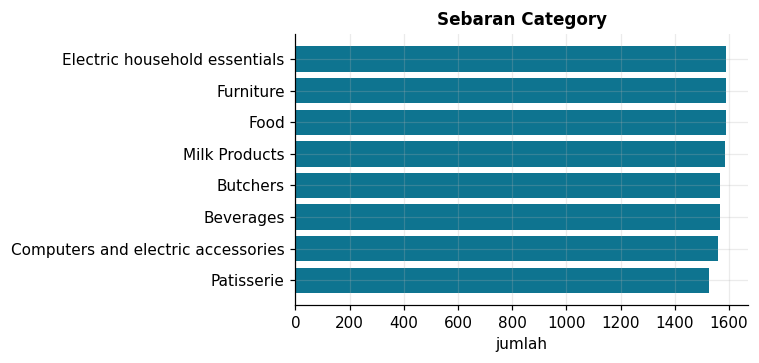

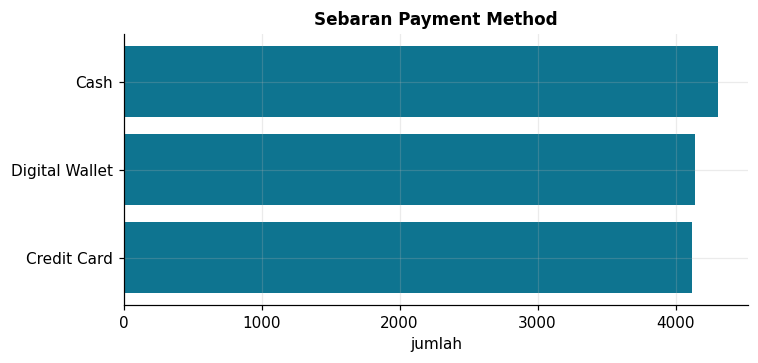

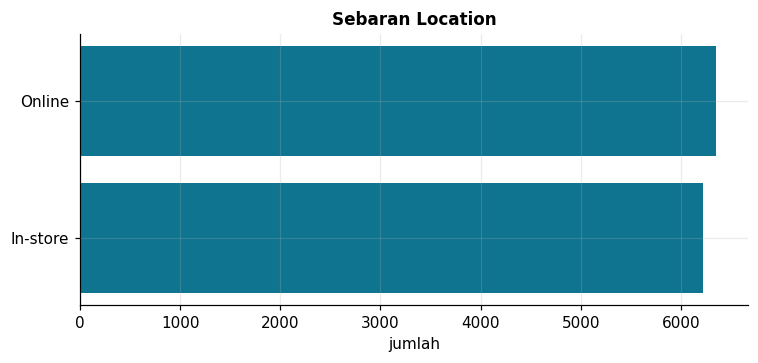

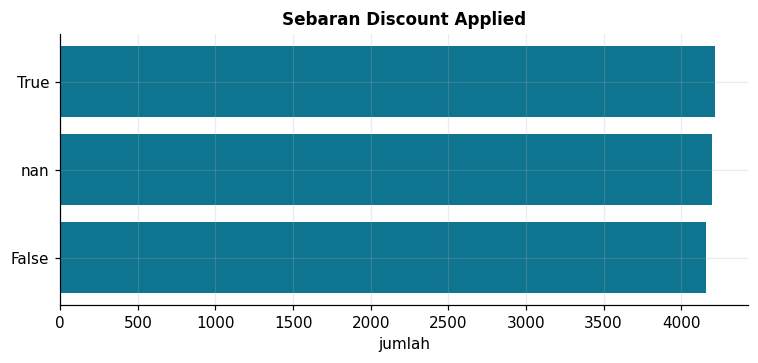

In [ ]:
for k in KATEGORIKAL:
    vc = df[k].value_counts(dropna=False).head(12)
    fig, ax = plt.subplots(figsize=(7, 3.4))
    ax.barh(vc.index[::-1].astype(str), vc.values[::-1], color=DATA)
    ax.set_xlabel('jumlah'); ax.set_title(f'Sebaran {k}')
    plt.tight_layout(); plt.show()


**Tafsiran.** Adakah kategori yang mendominasi? Adakah kategori dengan jumlah terlalu
sedikit sehingga statistiknya tidak dapat dipercaya nanti?

> _Dari 12.575 baris, tidak ada kategori yang mendominasi. Category terbagi hampir merata di 8 kelompok (12,2%-12,7% per kategori, 1.528-1.591 baris). Payment Method juga seimbang (Cash 34,3%, Digital Wallet 33,0%, Credit Card 32,8%), begitu pula Location (Online 50,5%, In-store 49,5%). Tidak ada kategori dengan jumlah yang terlalu sedikit (yang terkecil, Patisserie, masih 1.528 baris), sehingga perbandingan antar kategori nanti aman secara jumlah. Discount Applied berisi True 33,6%, False 33,1%, dan kosong 33,4% (4.199 baris). Karena sepertiga data tidak diketahui, kami memperlakukannya sebagai kategori tersendiri (“tidak diketahui”) agar tidak menghilangkan banyak baris; alternatif membuangnya akan memangkas n sekitar sepertiga. Sebaran yang sangat merata ini tidak lazim pada data transaksi nyata dan dapat mengindikasikan data sintetis; kami akan menguji di analisis bivariat apakah ada asosiasi antar kategori._


```

## 4. Ringkasan temuan univariat

| Variabel | Bentuk distribusi | Pemusatan yang dipakai | Outlier | Catatan untuk analisis berikutnya |
|----------|-------------------|------------------------|---------|-----------------------------------|
| Price Per Unit | Hampir merata dan simetris, histogram bergerigi karena harga diskrit (5–41) | Median (23,00); mean 23,37 hampir sama | Tidak ada (0 menurut IQR dan \|z\| > 3) | Sebagian nilai diimputasi dari Total ÷ Quantity (n = 12.575); Total Spent dihitung dari harga × jumlah, jadi korelasinya bersifat mekanis |
| Quantity | Hampir seragam, skewness ≈ −0,01 (1–10) | Median (6,00); mean 5,54 juga dapat dipakai, tetapi keduanya kurang informatif pada sebaran rata | Tidak ada (0) | n = 11.971 (604 kosong); bersifat diskrit, jadi pertimbangkan Spearman |
| Total Spent | Miring ke kanan (mean 129,65 > median 108,5) | Median (108,5), karena mean tertarik ekor kanan | 60 menurut IQR, semuanya 410 (= 41 × 10); sah, dipertahankan; \|z\| > 3 menandai 0 | Pakai Spearman atau bandingkan dengan Pearson; n = 11.971 |
| Category | 8 kelompok hampir merata (12,2%–12,7%) | Frekuensi dan proporsi | Tidak berlaku | Semua kelompok cukup besar (≥ 1.528 baris) untuk dibandingkan |
| Payment Method | 3 kelompok seimbang (32,8%–34,3%) | Frekuensi dan proporsi | Tidak berlaku | Aman untuk crosstab dan Cramér's V |
| Location | 2 kelompok seimbang (Online 50,5%, In-store 49,5%) | Frekuensi dan proporsi | Tidak berlaku | Cocok untuk faceting scatter plot |
| Discount Applied | True 33,6%, False 33,1%, kosong 33,4% | Frekuensi dan proporsi | Tidak berlaku | Kosong (4.199 baris) diperlakukan sebagai kategori "tidak diketahui" |

## Checklist sebelum mengumpulkan

- [x] Setiap variabel yang dianalisis memiliki tafsiran, bukan hanya grafik.
- [x] Bentuk distribusi dinyatakan dengan bukti dari gambar **dan** dari angka.
- [x] Pilihan mean atau median disertai alasan.
- [x] Keputusan tentang outlier dicatat beserta alasannya; tidak ada yang dibuang tanpa diperiksa.
- [x] Setiap grafik memiliki judul, label sumbu, dan satuan.
- [x] n yang dilaporkan adalah n setelah `dropna()`.
- [x] Restart & Run All berjalan tanpa galat.